# TO DO:
- Требуется найти безусловный минимум функции на отрезке [a, b], где функция является унимодальной. 
- привести задачу к задаче минимизации
- Составить отчёт в ворд по проделанной работе


|функция|a|b|ε|метод1|метод2|метод3| 
| --- | --- | --- | --- | --- | --- | --- |  
|f(x) = -xe^x|-2|6|0,001|1|5|8|

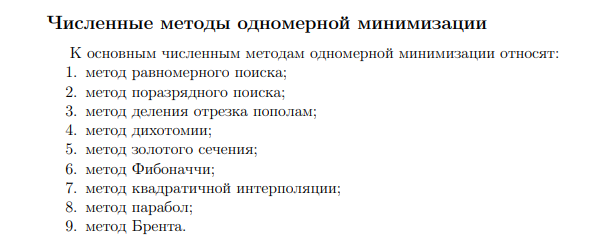

In [ ]:
import math
import pandas as pd
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook" #Требуется для нормальной работы plotly в Jupiter Notebook

# Ах, мой перебор, перебор
def uniformSearch(func, a, b, e):
    fx = []
    N = int((b - a) / e)
    minx = int() #чисто для сверки результатов с Desmos
    miny = int()
    for i in range(0, N):
        x = a + (i*(b-a))/N
        y = eval(func)
        fx.append([x, y])
        if y < miny:
            minx = x
            miny = y
    df = pd.DataFrame(fx, columns=['x', 'y'])
    fig = px.line(df, x='x', y='y', width=800, title='x*e^x')
    fig.show()
    return miny

# метод нахождения безусловного минимума при помощи золотого сечения
def goldenRatio(func, a, b, e): 
    te = 2 / (1 + math.sqrt(5))
    x1 = b - (b - a) * te
    x2 = a + (b - a) * te
    x = x1
    f1 = eval(func)
    x = x2
    f2 = eval(func)
    while (b-a > e):
        if f1 > f2: 
            a = x1
            x1 = x2
            f1 = f2
            x2 = b + a - x1
            x = x2
            f2 = eval(func)
        else:
            b = x2
            x2 = x1
            f2 = f1
            x1 = b + a - x2
            x = x1
            f1 = eval(func)
    return min(f1, f2)

# Мяу, мяу не понимать, сложна, разобраться когда мозги встанут на место (иди спать)
def parabolInterpol(func, a, b, e):
    t = [0, 0, 0]
    te = 2 / (1 + math.sqrt(5))
    x1 = b - (b - a) * te
    x2 = a + (b - a) * te
    x = x1
    f1 = eval(func)
    x = x2
    f2 = eval(func)
    for i in range(0, 2):
        if f1 > f2: 
            a = x1
            x1 = x2
            f1 = f2
            x2 = b + a - x1
            x = x2
            f2 = eval(func)
        else:
            b = x2
            x2 = x1
            f2 = f1
            x1 = b + a - x2
            x = x1
            f1 = eval(func)
        t[0], t[1], t[2] = a, x1, b
        if abs(a-x1) < e or abs(b-x1) < e:
            return x1

    a, c, b = t
    fs = c
    # За этой чертой бога нет. Хрень лютая.
    
    while (abs(b-a) > e):
        x = a
        fa = eval(func)
        x = b
        fb = eval(func)
        x = c
        fc = eval(func)

        s = c + (1/2)*((b-c)**2 * (fa-fc) - (c-a)**2 * (fb - fc))/((b-c) * (fa - fc) + (c - a) * (fb - fc)) #минимальная точка
        
        x = s
        fs = eval(func) 

        if s == c: 
            a = (a+c)/2
        if s < c:
            if fs < fc:
                a = c
                c = s
            else:
                b = s
        else:
            if fs < fc:
                b = c
                c = s
            else:
                a = s
        print(a, c, b)

    return fs

#print(uniformSearch("x*math.exp(1)**x", -2, 6, 0.001))
#print(goldenRatio("x*math.exp(1)**x", -2, 6, 0.001))
print(parabolInterpol("x*math.exp(1)**x", -2, 6, 0.001))


0.43289922666781827 -0.832815729997475 1.0557280900008417
-0.3128837486594201 -0.832815729997475 1.0557280900008417
-0.1217469548493358 -0.832815729997475 1.0557280900008417
-0.17436744988861796 -0.832815729997475 1.0557280900008417
-0.16012323325832428 -0.832815729997475 1.0557280900008417
-0.16399744448970674 -0.832815729997475 1.0557280900008417
-0.1629450625383623 -0.832815729997475 1.0557280900008417
-0.16323102865654132 -0.832815729997475 1.0557280900008417
-0.16315332977911648 -0.832815729997475 1.0557280900008417
-0.16317444161773764 -0.832815729997475 1.0557280900008417
-0.16316870528491087 -0.832815729997475 1.0557280900008417
-0.16317026391640913 -0.832815729997475 1.0557280900008417
-0.16316984041746488 -0.832815729997475 1.0557280900008417
-0.16316995548724314 -0.832815729997475 1.0557280900008417
-0.16316992422139567 -0.832815729997475 1.0557280900008417
-0.16316993271670388 -0.832815729997475 1.0557280900008417
-0.16316993040842606 -0.832815729997475 1.0557280900008417
-